
# CAUSALMIND AI
### Causal Failure Intelligence Engine
Detect unusual system behavior, prioritize potential causes,
and simulate interventions in a synthetic system.


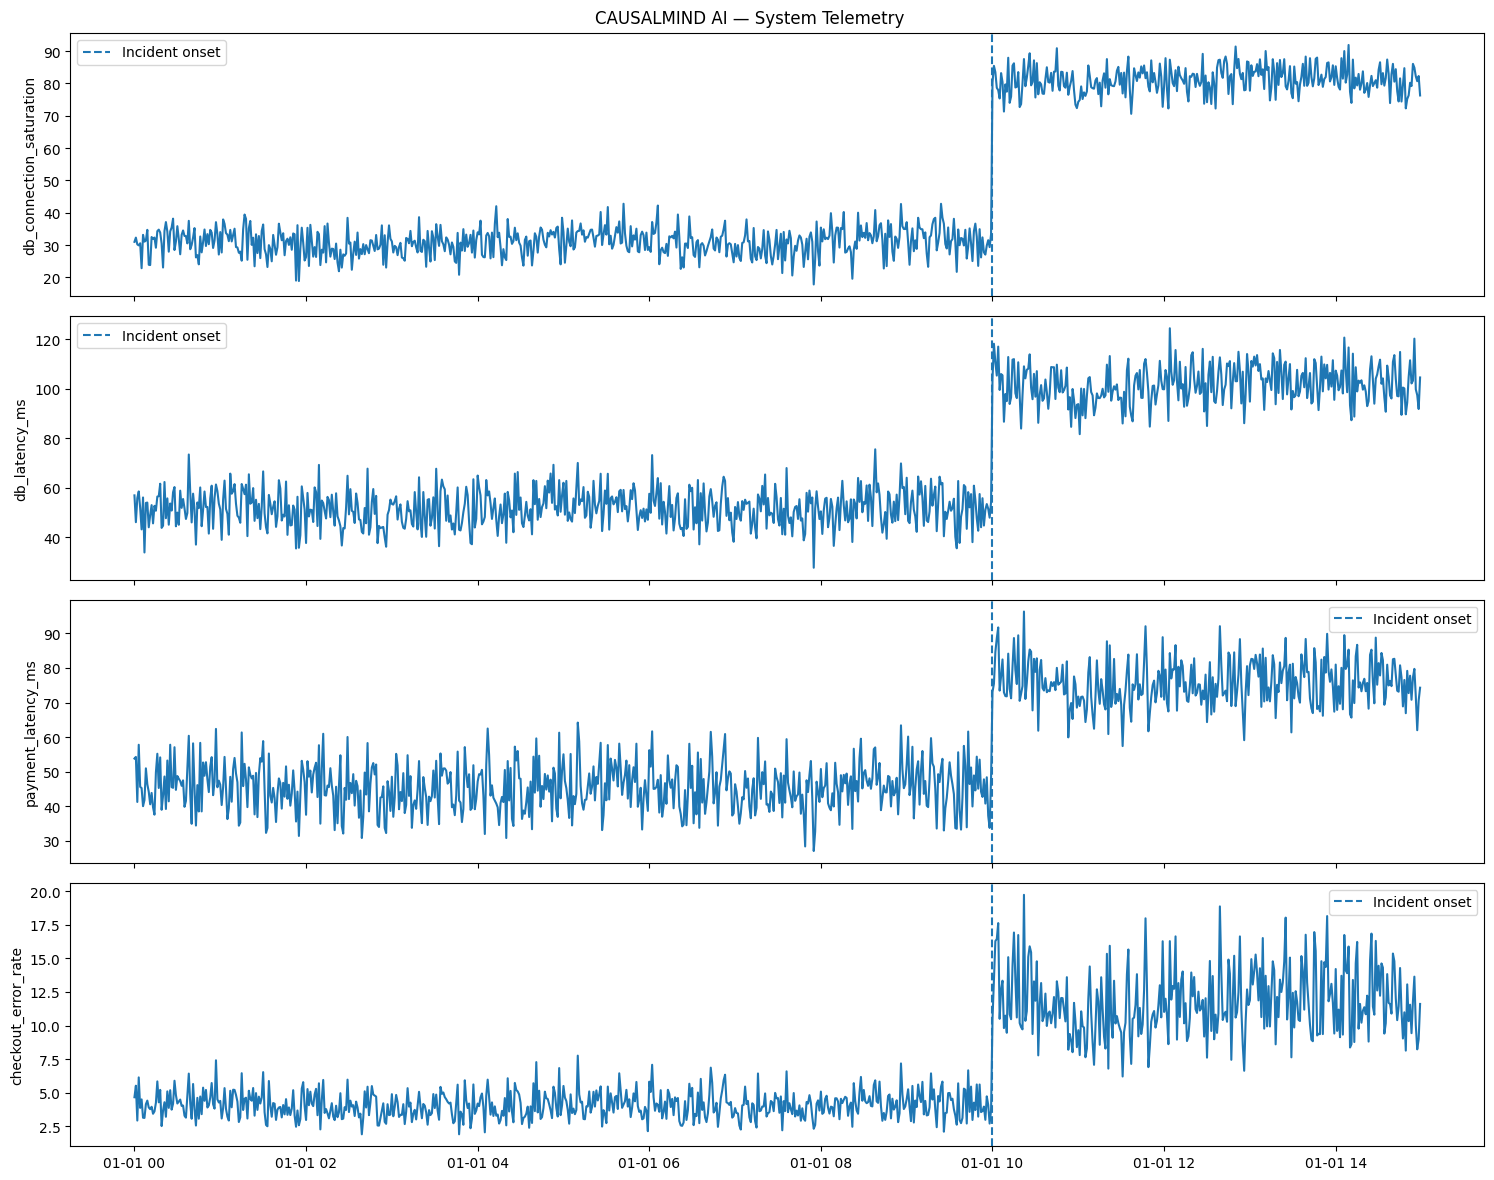

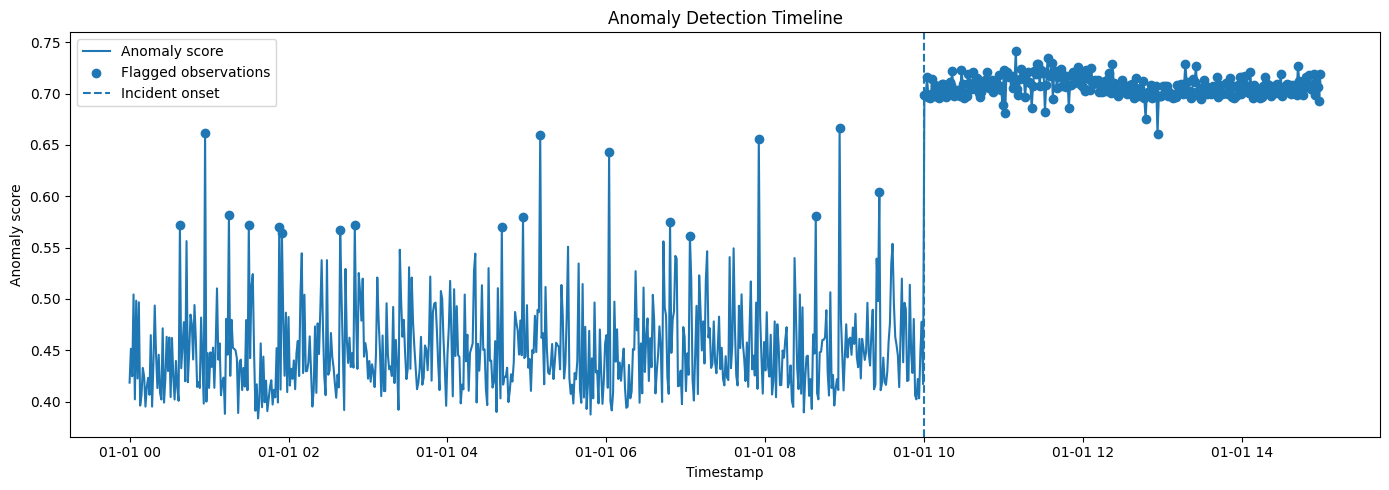

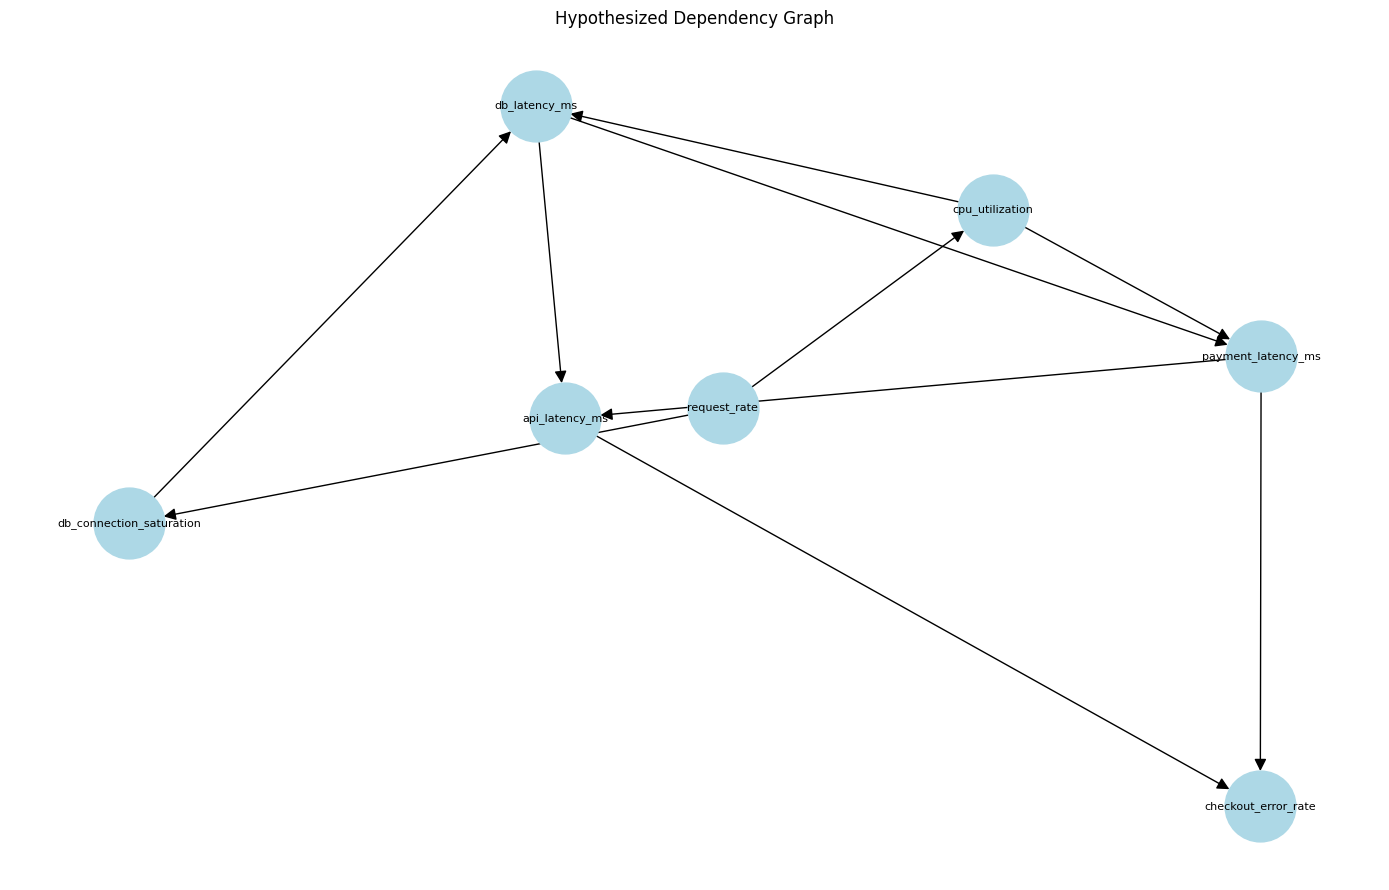

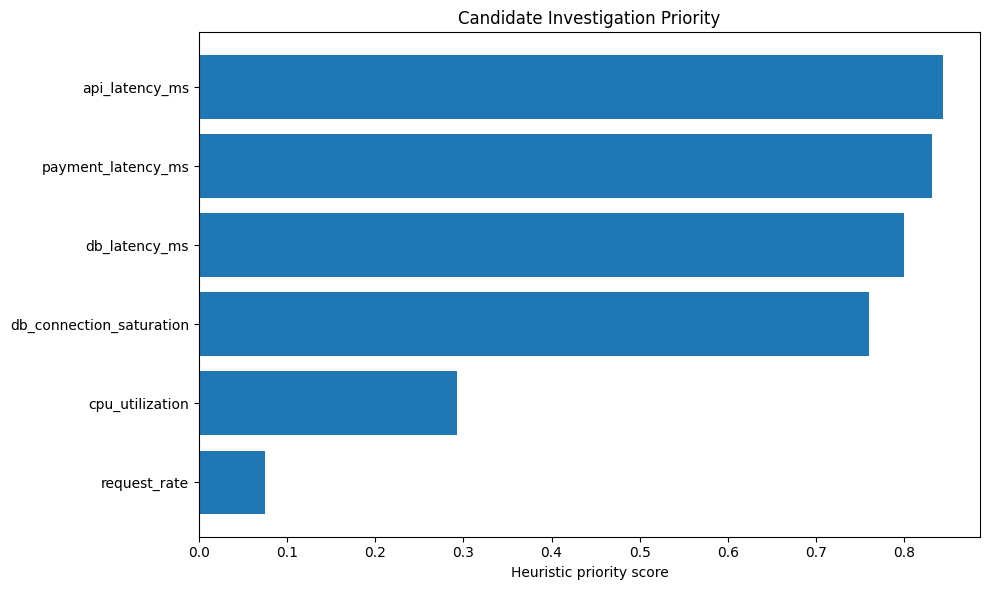

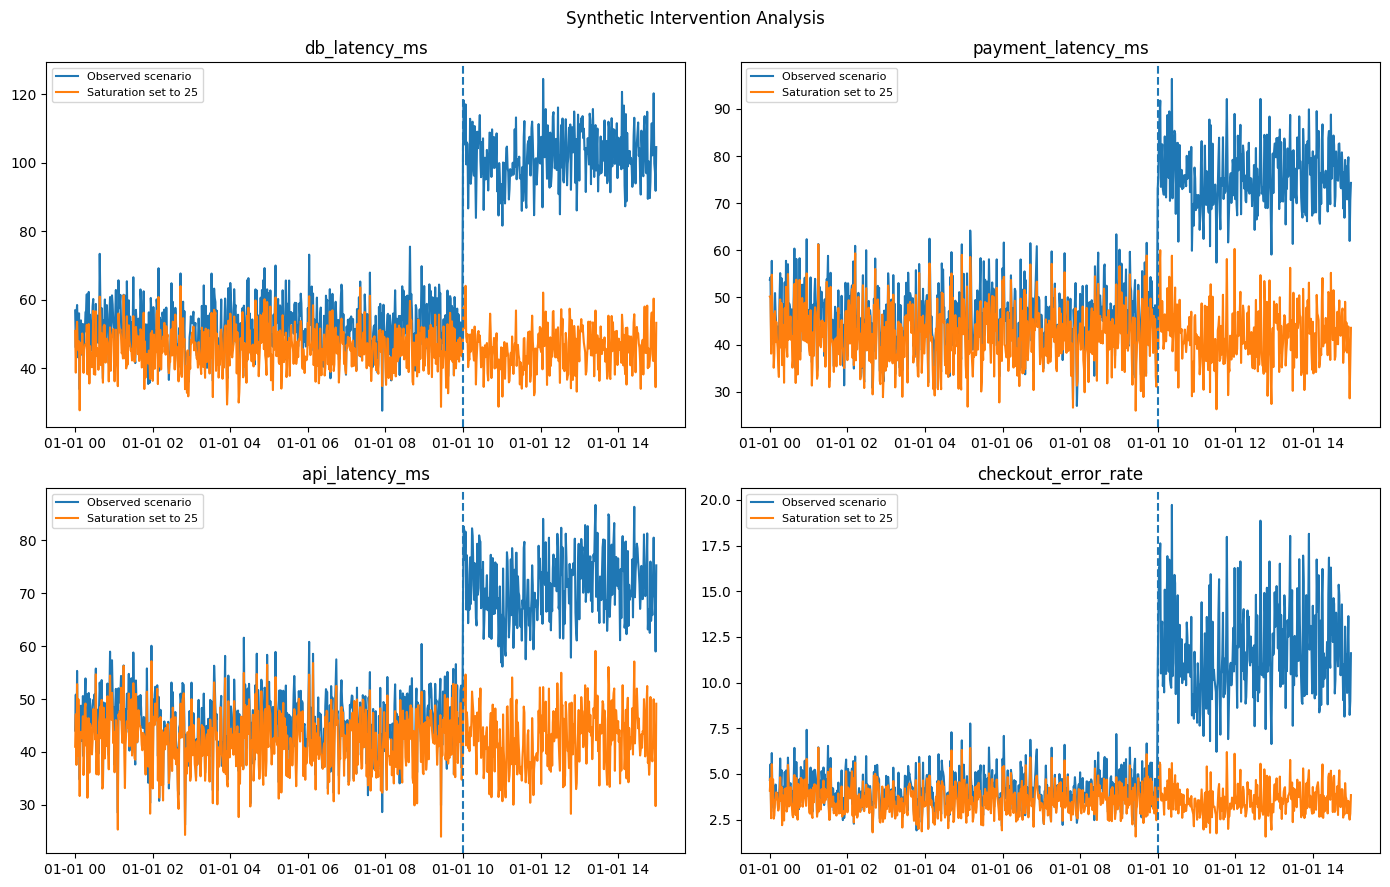

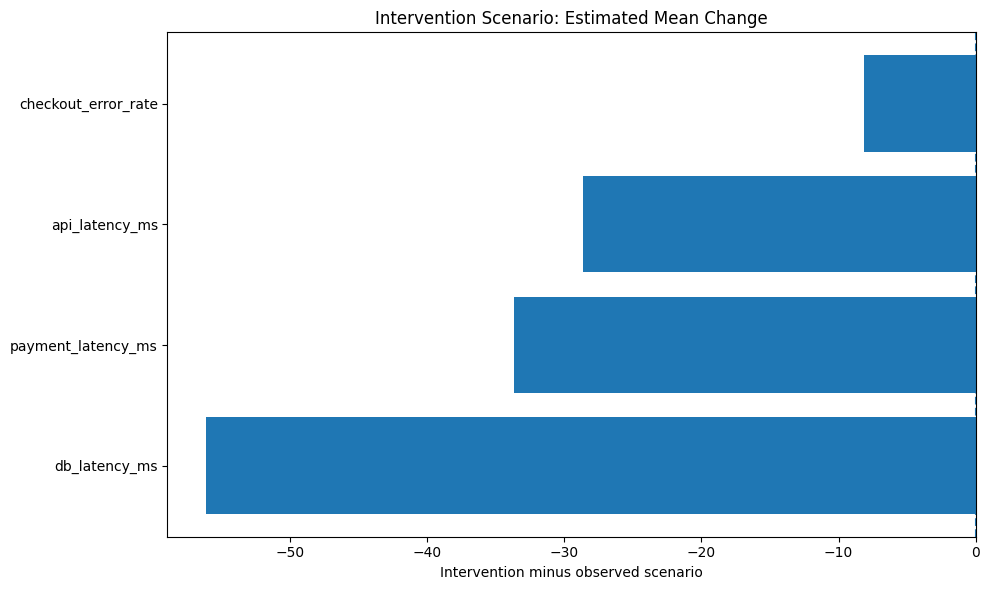

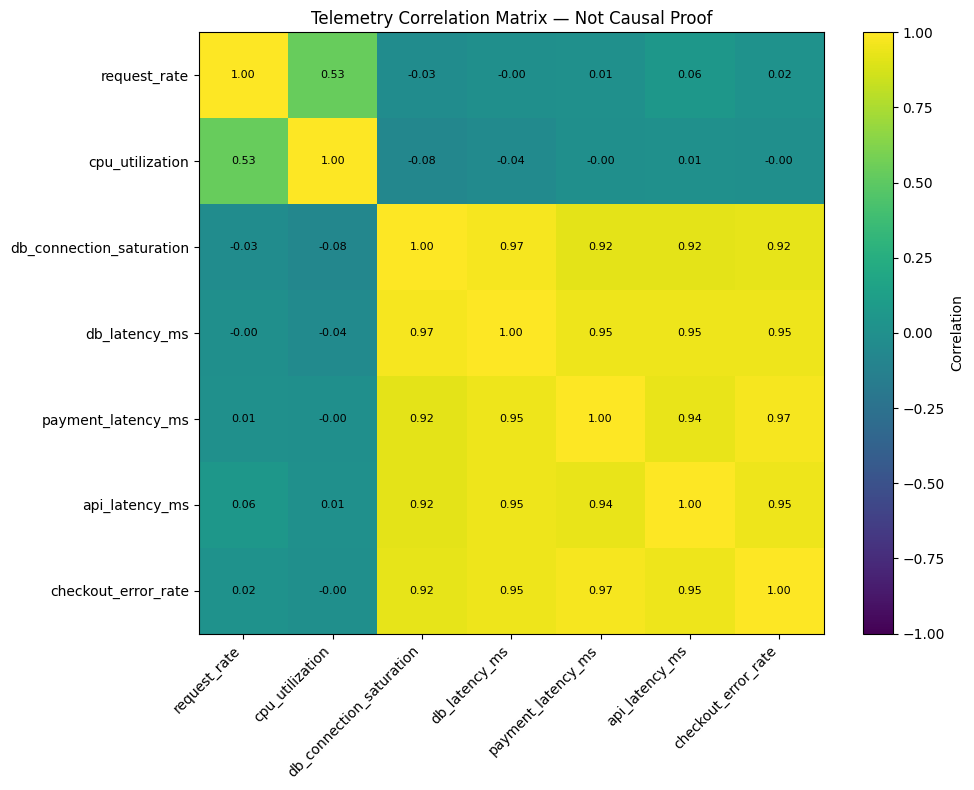

## Executive Summary

,metric,value
0,Total rows,900
1,Total columns,9
2,Missing cells,0
3,Duplicate timestamps,0
4,Chronological ordering,True


## Data Quality Report

,data_type,missing_count,unique_values,quality_status
timestamp,datetime64[ns],0,900,Passed basic checks
request_rate,float64,0,900,Passed basic checks
cpu_utilization,float64,0,900,Passed basic checks
db_connection_saturation,float64,0,900,Passed basic checks
db_latency_ms,float64,0,900,Passed basic checks
payment_latency_ms,float64,0,900,Passed basic checks
api_latency_ms,float64,0,900,Passed basic checks
checkout_error_rate,float64,0,900,Passed basic checks
incident_truth,int64,0,2,Passed basic checks


## Anomaly Evaluation

...

## Intervention Results

,outcome,observed_scenario_mean,intervention_scenario_mean,estimated_change,percent_change
0,db_latency_ms,101.8233,45.6939,-56.1294,-55.1243
1,payment_latency_ms,75.6890,42.0114,-33.6776,-44.4947
2,api_latency_ms,71.3874,42.7614,-28.6260,-40.0995
3,checkout_error_rate,11.7608,3.6004,-8.1604,-69.3867


## Highest-Scoring Anomalies

,timestamp,db_connection_saturation,db_latency_ms,payment_latency_ms,checkout_error_rate,anomaly_score,anomaly_flag
669,2026-01-01 11:09:00,78.812776,98.598596,71.603289,10.926483,0.741733,1
693,2026-01-01 11:33:00,75.672463,88.830254,73.405105,10.199763,0.734906,1
696,2026-01-01 11:36:00,78.206702,92.719847,68.438485,9.234997,0.729654,1
797,2026-01-01 13:17:00,83.711753,112.347999,81.053700,14.116322,0.728956,1
686,2026-01-01 11:26:00,80.617939,99.612762,69.643136,10.153146,0.728922,1
685,2026-01-01 11:25:00,79.126899,100.972544,82.619187,13.331110,0.728432,1
742,2026-01-01 12:22:00,78.873824,98.348834,72.013051,11.208592,0.728429,1
882,2026-01-01 14:42:00,84.378628,104.006617,78.023649,12.024233,0.727037,1
805,2026-01-01 13:25:00,79.086058,110.944456,88.724993,18.026028,0.726951,1
716,2026-01-01 11:56:00,79.317674,101.374897,79.195521,11.501290,0.725522,1



CAUSALMIND AI — COMPLETE EXECUTION
Rows: 900
Flagged anomalies: 318
Incident starts: 2026-01-01 10:00:00
Peak anomaly timestamp: 2026-01-01 11:09:00
Output directory: /content/CAUSALMIND_results

Generated files:
 - 01_telemetry.png
 - 02_anomalies.png
 - 03_dependency_graph.png
 - 04_root_cause_priority.png
 - 05_intervention_comparison.png
 - 06_intervention_effects.png
 - 07_correlation_matrix.png
 - anomaly_evaluation.csv
 - data_quality_report.csv
 - data_quality_summary.csv
 - flagged_anomalies.csv
 - intervention_results.csv
 - metadata.json
 - root_cause_candidates.csv
 - synthetic_telemetry.csv


In [1]:

# =============================================================================
# CAUSALMIND AI — COMPLETE ONE-CELL PROJECT
# Causal Failure Intelligence Engine
# Data Engineering + Machine Learning + Causal Simulation + Visualization
# =============================================================================

import sys, subprocess, importlib.util, warnings, json
from pathlib import Path

warnings.filterwarnings("ignore")

# 1. Install dependencies when missing
for module, package in [
    ("numpy", "numpy"),
    ("pandas", "pandas"),
    ("matplotlib", "matplotlib"),
    ("sklearn", "scikit-learn"),
    ("networkx", "networkx")
]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-q", package]
        )

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay
)
from IPython.display import display, Markdown

# 2. CONFIGURATION
SEED = 42
N = 900
INCIDENT_START = 600
OUTPUT_DIR = Path("CAUSALMIND_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

rng = np.random.default_rng(SEED)

display(Markdown("""
# CAUSALMIND AI
### Causal Failure Intelligence Engine
Detect unusual system behavior, prioritize potential causes,
and simulate interventions in a synthetic system.
"""))

# 3. SYNTHETIC TELEMETRY GENERATION
time_index = np.arange(N)
timestamps = pd.date_range(
    "2026-01-01", periods=N, freq="min"
)

request_rate = np.maximum(
    100 + 20 * np.sin(time_index / 40)
    + rng.normal(0, 8, N), 10
)

cpu_utilization = np.clip(
    30 + 0.16 * request_rate + rng.normal(0, 4, N),
    0, 100
)

incident_truth = (
    time_index >= INCIDENT_START
).astype(int)

# Inject a database connection saturation incident.
saturation = np.clip(
    25 + 0.06 * request_rate
    + 50 * incident_truth
    + rng.normal(0, 4, N),
    0, 100
)

# Structural equations with known synthetic relationships.
noise_db = rng.normal(0, 6, N)
noise_payment = rng.normal(0, 5, N)
noise_api = rng.normal(0, 4, N)
noise_error = rng.normal(0, 0.3, N)

db_latency = np.maximum(
    15 + 1.0 * saturation
    + 0.12 * cpu_utilization + noise_db, 1
)

payment_latency = np.maximum(
    10 + 0.60 * db_latency
    + 0.10 * cpu_utilization + noise_payment, 1
)

api_latency = np.maximum(
    10 + 0.30 * db_latency
    + 0.35 * payment_latency
    + 0.04 * request_rate + noise_api, 1
)

logit = (
    -5.0 + 0.025 * payment_latency
    + 0.015 * api_latency
)

error_probability = 1 / (
    1 + np.exp(-np.clip(logit, -20, 20))
)

checkout_error_rate = np.clip(
    100 * error_probability + noise_error, 0, 100
)

telemetry = pd.DataFrame({
    "timestamp": timestamps,
    "request_rate": request_rate,
    "cpu_utilization": cpu_utilization,
    "db_connection_saturation": saturation,
    "db_latency_ms": db_latency,
    "payment_latency_ms": payment_latency,
    "api_latency_ms": api_latency,
    "checkout_error_rate": checkout_error_rate,
    "incident_truth": incident_truth
})

# 4. DATA QUALITY AUDIT
quality_report = pd.DataFrame({
    "data_type": telemetry.dtypes.astype(str),
    "missing_count": telemetry.isna().sum(),
    "unique_values": telemetry.nunique()
})

quality_report["quality_status"] = np.where(
    quality_report["missing_count"] > 0,
    "Investigate",
    "Passed basic checks"
)

quality_summary = pd.DataFrame({
    "metric": [
        "Total rows",
        "Total columns",
        "Missing cells",
        "Duplicate timestamps",
        "Chronological ordering"
    ],
    "value": [
        len(telemetry),
        len(telemetry.columns),
        int(telemetry.isna().sum().sum()),
        int(telemetry["timestamp"].duplicated().sum()),
        bool(telemetry["timestamp"].is_monotonic_increasing)
    ]
})

# 5. FEATURE SELECTION AND BASELINE PREPROCESSING
features = [
    "request_rate",
    "cpu_utilization",
    "db_connection_saturation",
    "db_latency_ms",
    "payment_latency_ms",
    "api_latency_ms",
    "checkout_error_rate"
]

baseline = telemetry.loc[
    telemetry["incident_truth"] == 0, features
]

imputer = SimpleImputer(strategy="median")
baseline_imputed = imputer.fit_transform(baseline)

scaler = StandardScaler()
baseline_scaled = scaler.fit_transform(baseline_imputed)

all_imputed = imputer.transform(telemetry[features])
all_scaled = scaler.transform(all_imputed)

# 6. UNSUPERVISED ANOMALY DETECTION
detector = IsolationForest(
    n_estimators=300,
    contamination=0.03,
    random_state=SEED,
    n_jobs=-1
)

detector.fit(baseline_scaled)

telemetry["anomaly_score"] = (
    -detector.score_samples(all_scaled)
)

telemetry["anomaly_flag"] = (
    detector.predict(all_scaled) == -1
).astype(int)

# Standardized deviations from the baseline.
baseline_mean = baseline.mean()
baseline_std = baseline.std().replace(0, 1)

z_scores = (
    telemetry[features] - baseline_mean
) / baseline_std

# 7. DEFINE A HYPOTHESIZED CAUSAL DEPENDENCY GRAPH
G = nx.DiGraph()

edges = [
    ("request_rate", "cpu_utilization"),
    ("request_rate", "db_connection_saturation"),
    ("cpu_utilization", "db_latency_ms"),
    ("db_connection_saturation", "db_latency_ms"),
    ("db_latency_ms", "payment_latency_ms"),
    ("cpu_utilization", "payment_latency_ms"),
    ("db_latency_ms", "api_latency_ms"),
    ("payment_latency_ms", "api_latency_ms"),
    ("payment_latency_ms", "checkout_error_rate"),
    ("api_latency_ms", "checkout_error_rate")
]

G.add_edges_from(edges)

# These edges are known synthetic assumptions, not discovered facts.

# 8. SELECT THE MOST UNUSUAL INCIDENT OBSERVATION
incident_indices = telemetry.index[
    telemetry["incident_truth"] == 1
]

peak_index = telemetry.loc[
    incident_indices, "anomaly_score"
].idxmax()

peak_row = telemetry.loc[peak_index]
peak_timestamp = peak_row["timestamp"]

# 9. ROOT-CAUSE CANDIDATE PRIORITIZATION
# Transparent heuristic, not proof of causation.
target = "checkout_error_rate"

candidates = [
    "request_rate",
    "cpu_utilization",
    "db_connection_saturation",
    "db_latency_ms",
    "payment_latency_ms",
    "api_latency_ms"
]

candidate_rows = []

for node in candidates:
    z_value = float(z_scores.loc[peak_index, node])

    # Higher positive deviations are more concerning for these metrics.
    anomaly_evidence = float(
        np.clip(z_value / 4, 0, 1)
    )

    try:
        distance = nx.shortest_path_length(G, node, target)
        graph_evidence = 1 / (1 + distance)
    except nx.NetworkXNoPath:
        graph_evidence = 0.0

    threshold = (
        baseline_mean[node] + 2 * baseline_std[node]
    )

    crossed = np.where(
        telemetry[node].to_numpy() > threshold
    )[0]

    first_crossing = (
        int(crossed[0]) if len(crossed) else N
    )

    candidate_rows.append({
        "candidate": node,
        "positive_z_score": z_value,
        "anomaly_evidence": anomaly_evidence,
        "graph_evidence": graph_evidence,
        "first_threshold_crossing": first_crossing
    })

ranking = pd.DataFrame(candidate_rows)

onset = ranking["first_threshold_crossing"].to_numpy()

if onset.max() == onset.min():
    temporal_priority = np.ones(len(onset))
else:
    temporal_priority = 1 - (
        (onset - onset.min()) /
        (onset.max() - onset.min())
    )

ranking["temporal_priority"] = temporal_priority

ranking["priority_score"] = (
    0.50 * ranking["anomaly_evidence"]
    + 0.30 * ranking["graph_evidence"]
    + 0.20 * ranking["temporal_priority"]
)

ranking = ranking.sort_values(
    "priority_score", ascending=False
).reset_index(drop=True)

ranking.insert(
    0, "rank", np.arange(1, len(ranking) + 1)
)

# 10. STRUCTURAL INTERVENTION SIMULATION
# Reuse the same exogenous disturbances to compare worlds.
# This is valid only under this specified synthetic model.

def simulate_intervention(saturation_value=None):
    if saturation_value is None:
        sat = saturation.copy()
    else:
        sat = np.full(N, saturation_value, dtype=float)

    db = np.maximum(
        15 + sat + 0.12 * cpu_utilization + noise_db,
        1
    )

    payment = np.maximum(
        10 + 0.60 * db
        + 0.10 * cpu_utilization + noise_payment,
        1
    )

    api = np.maximum(
        10 + 0.30 * db
        + 0.35 * payment
        + 0.04 * request_rate + noise_api,
        1
    )

    p = 1 / (
        1 + np.exp(-np.clip(
            -5.0 + 0.025 * payment + 0.015 * api,
            -20, 20
        ))
    )

    errors = np.clip(
        100 * p + noise_error, 0, 100
    )

    return pd.DataFrame({
        "db_connection_saturation": sat,
        "db_latency_ms": db,
        "payment_latency_ms": payment,
        "api_latency_ms": api,
        "checkout_error_rate": errors
    })

observed_world = simulate_intervention()
intervention_world = simulate_intervention(
    saturation_value=25
)

incident_slice = slice(INCIDENT_START, N)

intervention_rows = []

for metric in [
    "db_latency_ms",
    "payment_latency_ms",
    "api_latency_ms",
    "checkout_error_rate"
]:
    observed_mean = observed_world[metric].iloc[
        incident_slice
    ].mean()

    intervention_mean = intervention_world[metric].iloc[
        incident_slice
    ].mean()

    difference = intervention_mean - observed_mean

    intervention_rows.append({
        "outcome": metric,
        "observed_scenario_mean": observed_mean,
        "intervention_scenario_mean": intervention_mean,
        "estimated_change": difference,
        "percent_change": (
            100 * difference / observed_mean
            if observed_mean != 0 else np.nan
        )
    })

intervention_results = pd.DataFrame(intervention_rows)

# 11. EVALUATE ANOMALY FLAGS AGAINST SYNTHETIC INCIDENT LABELS
# The incident labels identify the whole injected time interval.
# They do not identify the precise root cause.
y_true = telemetry["incident_truth"]
y_pred = telemetry["anomaly_flag"]

evaluation = pd.DataFrame({
    "metric": ["Precision", "Recall", "F1 score"],
    "value": [
        precision_score(y_true, y_pred, zero_division=0),
        recall_score(y_true, y_pred, zero_division=0),
        f1_score(y_true, y_pred, zero_division=0)
    ]
})

# 12. VISUALIZATION 1: TELEMETRY TIMELINE
fig, axes = plt.subplots(4, 1, figsize=(15, 12), sharex=True)

for ax, metric in zip(
    axes,
    [
        "db_connection_saturation",
        "db_latency_ms",
        "payment_latency_ms",
        "checkout_error_rate"
    ]
):
    ax.plot(
        telemetry["timestamp"], telemetry[metric]
    )
    ax.axvline(
        telemetry["timestamp"].iloc[INCIDENT_START],
        linestyle="--",
        label="Incident onset"
    )
    ax.set_ylabel(metric)
    ax.legend()

fig.suptitle("CAUSALMIND AI — System Telemetry")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "01_telemetry.png",
    dpi=160, bbox_inches="tight"
)
plt.show()

# 13. VISUALIZATION 2: ANOMALY DETECTION
plt.figure(figsize=(14, 5))

plt.plot(
    telemetry["timestamp"],
    telemetry["anomaly_score"],
    label="Anomaly score"
)

flagged = telemetry["anomaly_flag"] == 1

plt.scatter(
    telemetry.loc[flagged, "timestamp"],
    telemetry.loc[flagged, "anomaly_score"],
    label="Flagged observations"
)

plt.axvline(
    telemetry["timestamp"].iloc[INCIDENT_START],
    linestyle="--", label="Incident onset"
)

plt.title("Anomaly Detection Timeline")
plt.xlabel("Timestamp")
plt.ylabel("Anomaly score")
plt.legend()
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "02_anomalies.png",
    dpi=160, bbox_inches="tight"
)
plt.show()

# 14. VISUALIZATION 3: CAUSAL DEPENDENCY GRAPH
plt.figure(figsize=(14, 9))

positions = nx.spring_layout(G, seed=SEED, k=1.2)

nx.draw_networkx(
    G,
    positions,
    with_labels=True,
    node_size=2600,
    node_color="lightblue",
    font_size=8,
    arrows=True,
    arrowsize=18
)

plt.title("Hypothesized Dependency Graph")
plt.axis("off")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "03_dependency_graph.png",
    dpi=160, bbox_inches="tight"
)
plt.show()

# 15. VISUALIZATION 4: ROOT-CAUSE PRIORITY
plt.figure(figsize=(10, 6))

ordered = ranking.sort_values("priority_score")

plt.barh(
    ordered["candidate"],
    ordered["priority_score"]
)

plt.title("Candidate Investigation Priority")
plt.xlabel("Heuristic priority score")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "04_root_cause_priority.png",
    dpi=160, bbox_inches="tight"
)
plt.show()

# 16. VISUALIZATION 5: INTERVENTION COMPARISON
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, metric in zip(
    axes.flat,
    [
        "db_latency_ms",
        "payment_latency_ms",
        "api_latency_ms",
        "checkout_error_rate"
    ]
):
    ax.plot(
        telemetry["timestamp"],
        observed_world[metric],
        label="Observed scenario"
    )

    ax.plot(
        telemetry["timestamp"],
        intervention_world[metric],
        label="Saturation set to 25"
    )

    ax.axvline(
        telemetry["timestamp"].iloc[INCIDENT_START],
        linestyle="--"
    )

    ax.set_title(metric)
    ax.legend(fontsize=8)

fig.suptitle("Synthetic Intervention Analysis")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "05_intervention_comparison.png",
    dpi=160, bbox_inches="tight"
)
plt.show()

# 17. VISUALIZATION 6: ESTIMATED INTERVENTION EFFECTS
plt.figure(figsize=(10, 6))

plt.barh(
    intervention_results["outcome"],
    intervention_results["estimated_change"]
)

plt.axvline(0, linestyle="--")
plt.title("Intervention Scenario: Estimated Mean Change")
plt.xlabel("Intervention minus observed scenario")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "06_intervention_effects.png",
    dpi=160, bbox_inches="tight"
)
plt.show()

# 18. VISUALIZATION 7: CORRELATION HEATMAP
corr = telemetry[features].corr()

fig, ax = plt.subplots(figsize=(10, 8))

image = ax.imshow(
    corr, vmin=-1, vmax=1, aspect="auto"
)

ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")

ax.set_yticks(range(len(corr.index)))
ax.set_yticklabels(corr.index)

for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        ax.text(
            j, i, f"{corr.iloc[i, j]:.2f}",
            ha="center", va="center", fontsize=8
        )

ax.set_title("Telemetry Correlation Matrix — Not Causal Proof")
fig.colorbar(image, ax=ax, label="Correlation")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "07_correlation_matrix.png",
    dpi=160, bbox_inches="tight"
)
plt.show()

# 19. EXPORT RESULTS
telemetry.to_csv(
    OUTPUT_DIR / "synthetic_telemetry.csv",
    index=False
)

quality_report.to_csv(
    OUTPUT_DIR / "data_quality_report.csv"
)

quality_summary.to_csv(
    OUTPUT_DIR / "data_quality_summary.csv",
    index=False
)

ranking.to_csv(
    OUTPUT_DIR / "root_cause_candidates.csv",
    index=False
)

intervention_results.to_csv(
    OUTPUT_DIR / "intervention_results.csv",
    index=False
)

evaluation.to_csv(
    OUTPUT_DIR / "anomaly_evaluation.csv",
    index=False
)

telemetry.loc[flagged].to_csv(
    OUTPUT_DIR / "flagged_anomalies.csv",
    index=False
)

metadata = {
    "project": "CAUSALMIND AI",
    "seed": SEED,
    "sample_count": N,
    "incident_start_index": INCIDENT_START,
    "incident_start_timestamp": str(
        telemetry["timestamp"].iloc[INCIDENT_START]
    ),
    "peak_anomaly_timestamp": str(peak_timestamp),
    "algorithm": "IsolationForest",
    "graph": "Predefined synthetic structural assumptions",
    "ranking": "Heuristic investigation prioritization",
    "intervention": "Synthetic structural-equation simulation",
    "limitations": [
        "Synthetic data, not production telemetry",
        "Anomaly flags do not establish root cause",
        "The graph is predefined, not causally discovered",
        "Intervention results depend on structural equations"
    ]
}

with open(OUTPUT_DIR / "metadata.json", "w") as file:
    json.dump(metadata, file, indent=2)

# 20. FINAL REPORT
display(Markdown("## Executive Summary"))
display(quality_summary)

display(Markdown("## Data Quality Report"))
display(quality_report)

display(Markdown("## Anomaly Evaluation"))
display(evaluation.round(4))

display(Markdown("## Ranked Candidate Causes"))
display(ranking.round(4))

display(Markdown("## Intervention Results"))
display(intervention_results.round(4))

display(Markdown("## Highest-Scoring Anomalies"))
display(
    telemetry.sort_values(
        "anomaly_score", ascending=False
    )[
        [
            "timestamp",
            "db_connection_saturation",
            "db_latency_ms",
            "payment_latency_ms",
            "checkout_error_rate",
            "anomaly_score",
            "anomaly_flag"
        ]
    ].head(15)
)

print("\n" + "=" * 70)
print("CAUSALMIND AI — COMPLETE EXECUTION")
print("=" * 70)
print("Rows:", len(telemetry))
print("Flagged anomalies:", int(telemetry["anomaly_flag"].sum()))
print("Incident starts:", telemetry["timestamp"].iloc[INCIDENT_START])
print("Peak anomaly timestamp:", peak_timestamp)
print("Output directory:", OUTPUT_DIR.resolve())
print("\nGenerated files:")

for file in sorted(OUTPUT_DIR.iterdir()):
    print(" -", file.name)
